# MovieLens 32M - Exploratory Data Analysis

## AuraCinema - Movie Discovery Engine

This notebook is a data analysis project which explores the MovieLens 32M dataset as the data foundation that will be used further in a Machine Learning project: "AuraCinema Movie Recommendation System", an AI-powered application that produces personalised movie recommendations based in user's preferences.


## 1. Introduction

The objective of this exploratory data analysis (EDA) is to understand the structure, quality and characteristics of the MovieLens 32M dataset before developing the movie recommendation system.

The analysis will investigate the available data, user and movie activity, rating behaviour, movie genres and user–movie interactions.

The findings from this analysis will be used to guide subsequent data preprocessing and the design of the recommendation approach.

## 2. Dataset Overview

MovieLens 32M is a stable benchmark dataset provided by GroupLens. It contains movie ratings, movie metadata, user-generated tags and links to external movie databases.

The dataset will be used as the primary data source for developing and evaluating the recommendation system.

### 2.1 Dataset Components

The MovieLens 32M dataset is composed of four main data files:

| File | Description |
|---|---|
| `ratings.csv` | User ratings for movies |
| `movies.csv` | Movie titles and genre information |
| `tags.csv` | User-generated tags associated with movies |
| `links.csv` | Links between MovieLens movie IDs and external movie databases |

The `ratings.csv` file represents the main interaction data for the recommendation problem, while the other files provide additional information that may support data exploration and future recommendation features.

In [5]:
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

In [6]:
data_path = "../data/ml-32m/"

In [7]:
movies = pd.read_csv(data_path + "movies.csv")

In [9]:
movies.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [17]:
print('How many movies in the catalog?\n')

print(f'The catalog has {movies.shape[0]} movies, and {movies.shape[1]} main attributes, which are: \n\n{movies.columns}.')

How many movies in the catalog?

The catalog has 87585 movies, and 3 main attributes, which are: 

Index(['movieId', 'title', 'genres'], dtype='str').


In [18]:
print('Getting information about the dataset:\n')

movies.info()

Getting information about the dataset:

<class 'pandas.DataFrame'>
RangeIndex: 87585 entries, 0 to 87584
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   movieId  87585 non-null  int64
 1   title    87585 non-null  str  
 2   genres   87585 non-null  str  
dtypes: int64(1), str(2)
memory usage: 2.0 MB


### Initial observations

The `movies.csv` file contains 87,585 movie records and three columns: `movieId`, `title` and `genres`.

The `movieId` column provides the identifier used to connect movies with the other MovieLens files. The `title` column contains the movie title, including the release year when available. The `genres` column contains one or more genre labels for each movie.

### Notes on the ratings dataset:
 
The `ratings.csv` file contains over 32 million records. To avoid unnecessarily loading the complete dataset during the initial inspection, a sample of 10,000 records is used at this stage.

The full ratings dataset will be loaded or processed in chunks when required for subsequent analysis.

In [24]:
ratings_sample = pd.read_csv(data_path + 'ratings.csv', nrows=10000)

ratings_sample.head()

,userId,movieId,rating,timestamp
0,1,17,4.0,944249077
1,1,25,1.0,944250228
2,1,29,2.0,943230976
3,1,30,5.0,944249077
4,1,32,5.0,943228858


In [21]:
ratings_sample.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   userId     10000 non-null  int64  
 1   movieId    10000 non-null  int64  
 2   rating     10000 non-null  float64
 3   timestamp  10000 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 312.6 KB


In [23]:
tags = pd.read_csv(data_path + 'tags.csv')

tags.head()

,userId,movieId,tag,timestamp
0,22,26479,Kevin Kline,1583038886
1,22,79592,misogyny,1581476297
2,22,247150,acrophobia,1622483469
3,34,2174,music,1249808064
4,34,2174,weird,1249808102


In [25]:
links = pd.read_csv(data_path + 'links.csv')

links.head()

,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0
3,4,114885,31357.0
4,5,113041,11862.0


### Brief dataset overview:

In [26]:
dataset_overview = pd.DataFrame({
    "Dataset": ["Movies", "Ratings sample", "Tags", "Links"],
    "Rows": [
        len(movies),
        len(ratings_sample),
        len(tags),
        len(links)
    ],
    "Columns": [
        movies.shape[1],
        ratings_sample.shape[1],
        tags.shape[1],
        links.shape[1]
    ]
})

dataset_overview

,Dataset,Rows,Columns
0,Movies,87585,3
1,Ratings sample,10000,4
2,Tags,2000072,4
3,Links,87585,3


## 3. Data Quality

Before performing further analysis, the datasets need to be checked for missing values, duplicated records, unexpected values and other potential data quality issues.

This step is important because data quality problems can affect the reliability of subsequent analysis and recommendation models.

In [27]:
print('Are there any empty records in movies file?\n')

movies.isnull().sum()

Are there any empty records in movies file?



movieId    0
title      0
genres     0
dtype: int64

In [28]:
print('Are there any missing values in ratings sample?\n')

ratings_sample.isnull().sum()

Are there any missing values in ratings sample?



userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

In [29]:
print('Are there any missing tag values?\n')

tags.isnull().sum()

Are there any missing tag values?



userId        0
movieId       0
tag          17
timestamp     0
dtype: int64

In [30]:
print('Are there any missing link values?\n')

links.isnull().sum()

Are there any missing link values?



movieId      0
imdbId       0
tmdbId     124
dtype: int64

In [31]:
missing_values = pd.DataFrame({
    "Dataset": ["Movies", "Ratings Sample", "Tags", "Links"],
    "Missing Values": [
        movies.isnull().sum().sum(),
        ratings_sample.isnull().sum().sum(),
        tags.isnull().sum().sum(),
        links.isnull().sum().sum()
    ]
})

missing_values

,Dataset,Missing Values
0,Movies,0
1,Ratings Sample,0
2,Tags,17
3,Links,124


### Missing value observations

The initial inspection shows that the main movie and ratings fields do not contain missing values in the datasets or samples examined. A small number of missing values are present in the `tags` and `links` datasets.

The missing values in `tags` are limited to 17 records, while missing external identifiers in `links` do not affect the MovieLens `movieId`, which is the primary identifier used to connect the datasets.

These missing values will be considered during preprocessing, but they do not prevent the datasets from being used for exploratory analysis.

In [32]:
print('Are there any duplicated rows in movies?\n')

movies.duplicated().sum()

Are there any duplicated rows in movies?



np.int64(0)

In [33]:
print('Are there any duplicated rows in ratings sample?\n')

ratings_sample.duplicated().sum()

Are there any duplicated rows in ratings sample?



np.int64(0)

In [34]:
print('Are there any duplicated tags?\n')

tags.duplicated().sum()

Are there any duplicated tags?



np.int64(0)

In [36]:
print('How many different users are there in the dataset 10000 records sample?\n')

ratings_sample["userId"].nunique()

How many different users are there in the dataset 10000 records sample?



66

In [37]:
print('How many different movies are there in the first 10000 records?\n')

ratings_sample["movieId"].nunique()

How many different movies are there in the first 10000 records?



3965

In [41]:
print('Which different rating values are there in the 10000 records?\n')

ratings_sample["rating"].unique()

sorted(ratings_sample["rating"].unique())

Which different rating values are there in the 10000 records?



[np.float64(0.5),
 np.float64(1.0),
 np.float64(1.5),
 np.float64(2.0),
 np.float64(2.5),
 np.float64(3.0),
 np.float64(3.5),
 np.float64(4.0),
 np.float64(4.5),
 np.float64(5.0)]

In [42]:
print('Are there any rating values outside the range that was found in the last cell?\n')

ratings_sample[
    (ratings_sample["rating"] < 0.5) |
    (ratings_sample["rating"] > 5.0)
]

Are there any rating values outside the range that was found in the last cell?



,userId,movieId,rating,timestamp


In [44]:
print('Checking whether every movieId is actually unique within the catalog:\n')

if movies["movieId"].nunique() == len(movies):
    print('Yes, every movieId is unique inside the catalog.')

Checking whether every movieId is actually unique within the catalog:

Yes, every movieId is unique inside the catalog.


### Identifier observations

The `movieId` field is unique within the movie catalogue, making it suitable as the primary identifier for connecting movie metadata with ratings, tags and other MovieLens data.

The `userId` and `movieId` fields in the ratings data represent the two main entities involved in the recommendation problem: users and movies.

In [45]:
print('Movies and ratings datatypes:\n')

movies.dtypes

ratings_sample.dtypes

Movies and ratings datatypes:



userId         int64
movieId        int64
rating       float64
timestamp      int64
dtype: object

### Data Quality Summary

The initial data quality assessment indicates that the MovieLens dataset is structurally suitable for further analysis.

The main movie fields do not contain missing values, and the `movieId` identifier is unique within the movie catalogue. The ratings sample contains values within the expected rating range of 0.5 to 5.0.

A small number of missing values were identified in supplementary fields such as tags and external movie identifiers. These issues will be considered during preprocessing rather than during the initial exploratory analysis.

The `timestamp` field is currently stored as an integer and will be converted to a datetime representation when performing temporal analysis.

## 4. User Behaviour

Understanding user behaviour is important for a recommendation system because recommendations are based on interactions between users and movies.

This section investigates the number of users, the distribution of ratings across users and the level of user activity in the dataset.

In [50]:
ratings_chunks = pd.read_csv(data_path + "ratings.csv", chunksize=500_000)

The following code returns the total number of ratings, total number of unique users, and the number of ratings per different user. 

It uses the original 32 million records `movies.csv` file.

In [51]:
user_rating_counts = {}
total_ratings = 0

for chunk in ratings_chunks:
    total_ratings += len(chunk)

    counts = chunk["userId"].value_counts()

    for user_id, count in counts.items():
        user_rating_counts[user_id] = (user_rating_counts.get(user_id, 0) + count)

In [52]:
print(f"Total ratings: {total_ratings:,}")

Total ratings: 32,000,204


In [53]:
user_rating_counts = pd.Series(user_rating_counts)

In [57]:
# Number of different ratings (not users)
user_rating_counts.nunique()

# We need to check the lentgh to know how many different users
print(f'Number of unique users within 32 million records: {len(user_rating_counts)}')

Number of unique users within 32 million records: 200948


### User population

The MovieLens 32M dataset contains 200,948 unique users who collectively contributed 32,000,204 movie ratings.

The number of ratings is therefore substantially larger than the number of users, indicating that users typically interact with multiple movies.

In [62]:
print('Chencking who are the most active users in terms of ratings:\n')

user_rating_counts.head()

user_rating_counts.sort_values(ascending=False).head(100)

Chencking who are the most active users in terms of ratings:



175325    33332
17035      9577
55653      9178
123465     9044
171795     9016
          ...  
112964     3787
60568      3783
128508     3776
8901       3766
116907     3763
Length: 100, dtype: int64

In [66]:
print('Descriptive statistics:\n')

user_rating_counts.describe()

Descriptive statistics:



count    200948.000000
mean        159.246193
std         282.025462
min          20.000000
25%          36.000000
50%          73.000000
75%         167.000000
max       33332.000000
dtype: float64

In [64]:
print(f"Mean ratings per user: {user_rating_counts.mean():.2f}")
print(f"Median ratings per user: {user_rating_counts.median():.2f}")

Mean ratings per user: 159.25
Median ratings per user: 73.00


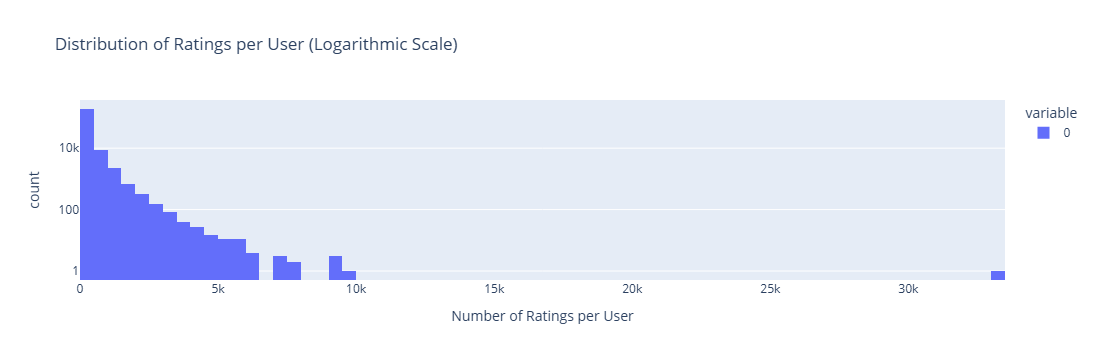

In [68]:
fig = px.histogram(
    user_rating_counts,
    nbins=100,
    log_y=True,
    title="Distribution of Ratings per User (Logarithmic Scale)",
    labels={
        "value": "Number of Ratings per User",
        "count": "Number of Users"
    })

fig.show()

### User activity observations

The distribution of ratings per user is highly skewed. Although the average user has approximately 159 ratings, the median is substantially lower, at around 73 ratings.

This difference indicates that a relatively small number of highly active users contribute a large number of ratings. The distribution is therefore not uniform across users.

The dataset also has a minimum of 20 ratings per user, which reflects the criteria used to construct the MovieLens 32M benchmark.

In [76]:
user_activity = pd.cut(
    user_rating_counts,
    bins=[0, 50, 100, 500, 1000, float("inf")],
    labels=["1–50", "51–100", "101–500", "500-1000", "1000+"])

user_activity.value_counts().sort_index()

1–50        74360
51–100      46874
101–500     67171
500-1000     8929
1000+        3614
Name: count, dtype: int64

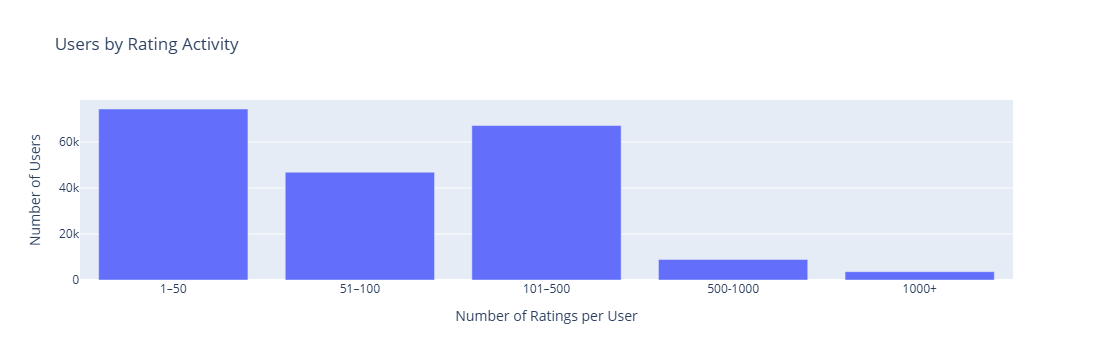

In [77]:
activity_counts = (
    user_activity
    .value_counts()
    .sort_index()
    .reset_index())

activity_counts.columns = ["activity_group", "user_count"]

fig = px.bar(
    activity_counts,
    x="activity_group",
    y="user_count",
    title="Users by Rating Activity",
    labels={
        "activity_group": "Number of Ratings per User",
        "user_count": "Number of Users"
    })

fig.show()

### User activity groups

Grouping users by the number of ratings highlights the uneven distribution of activity in the dataset.

Most users belong to the lower-activity groups, while a smaller number of users contribute substantially more ratings. This imbalance is relevant for recommendation systems because users with larger interaction histories provide more information about their preferences.

In [79]:
print('Discovering what proportion of all ratings comes from highly active users:\n')

activity_df = pd.DataFrame({"rating_count": user_rating_counts, "activity_group": user_activity})

activity_summary = (
    activity_df
    .groupby("activity_group", observed=True)["rating_count"]
    .agg(users="count", ratings="sum").reset_index())

activity_summary 

Discovering what proportion of all ratings comes from highly active users:



,activity_group,users,ratings
0,1–50,74360,2384520
1,51–100,46874,3361742
2,101–500,67171,14355372
3,500-1000,8929,6067441
4,1000+,3614,5831129


In [81]:
print('Which user groups generate most of the dataset\'s interactions:\n')

activity_summary["rating_percentage"] = (activity_summary["ratings"] / total_ratings * 100)

activity_summary

Which user groups generate most of the dataset's interactions:



,activity_group,users,ratings,rating_percentage
0,1–50,74360,2384520,7.451577
1,51–100,46874,3361742,10.505377
2,101–500,67171,14355372,44.860252
3,500-1000,8929,6067441,18.960632
4,1000+,3614,5831129,18.222162


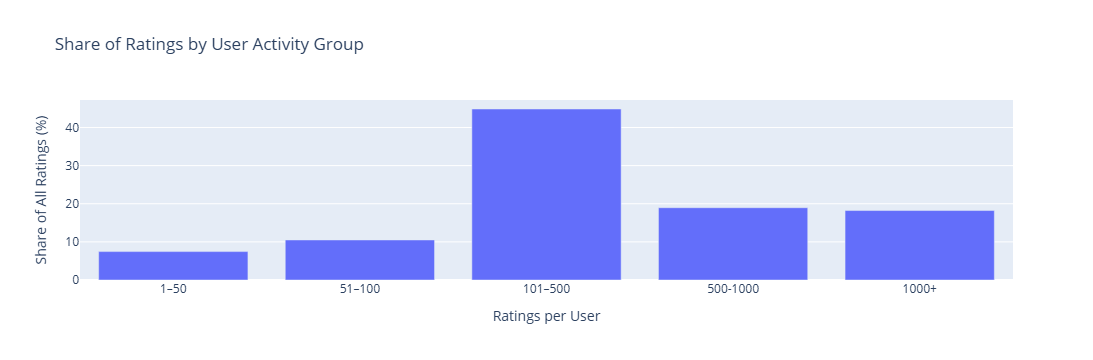

In [82]:
fig = px.bar(
    activity_summary,
    x="activity_group",
    y="rating_percentage",
    title="Share of Ratings by User Activity Group",
    labels={
        "activity_group": "Ratings per User",
        "rating_percentage": "Share of All Ratings (%)"
    })

fig.show()

### User behaviour and recommendation implications

The analysis shows that user activity is highly uneven. Most users have relatively small rating histories, while a smaller group of highly active users contributes a substantial number of interactions.

This has implications for recommendation systems. Users with more historical ratings provide richer information about their preferences, while users with fewer interactions present a more limited basis for personalization.

This observation will be considered when selecting the data used for model development and evaluation. However, user activity thresholds should be determined based on the requirements of the recommendation approach rather than being imposed uniquely from the exploratory analysis.

## 5. Movie Popularity

Movie popularity can be explored by examining the number of ratings received by each movie. This provides an overview of user engagement with the movie catalogue and helps identify differences between highly rated and less frequently rated movies.

This section analyses rating counts per movie and identifies the movies with the highest number of ratings. Rating count is used as a measure of popularity, rather than as a measure of movie quality.

In [84]:
# couting how many ratings each movie has received
movie_rating_counts = {}

ratings_chunks = pd.read_csv(data_path + "ratings.csv", chunksize=500_000)

for chunk in ratings_chunks:
    counts = chunk["movieId"].value_counts()

    for movie_id, count in counts.items():
        movie_rating_counts[movie_id] = (movie_rating_counts.get(movie_id, 0) + count)

In [85]:
# Converting the dictionary into a Pandas series. The Pandas series facilitates further statistics and visualization operations.
movie_rating_counts = pd.Series(movie_rating_counts)

movie_rating_counts.head()

318     102929
356     100296
296      98409
2571     93808
593      90330
dtype: int64

In [86]:
print('How many movies received ratings?\n')

print(f"Movies with ratings: {len(movie_rating_counts):,}")
print(f"Movies in catalogue: {len(movies):,}")

How many movies received ratings?

Movies with ratings: 84,432
Movies in catalogue: 87,585


In [87]:
# Understanding rating distribution
movie_rating_counts.describe()

count     84432.000000
mean        379.005638
std        2592.439791
min           1.000000
25%           2.000000
50%           5.000000
75%          25.000000
max      102929.000000
dtype: float64

In [88]:
print(f"Mean ratings per movie: {movie_rating_counts.mean():,.2f}")
print(f"Median ratings per movie: {movie_rating_counts.median():,.2f}")
print(f"Maximum ratings for a movie: {movie_rating_counts.max():,}")

Mean ratings per movie: 379.01
Median ratings per movie: 5.00
Maximum ratings for a movie: 102,929


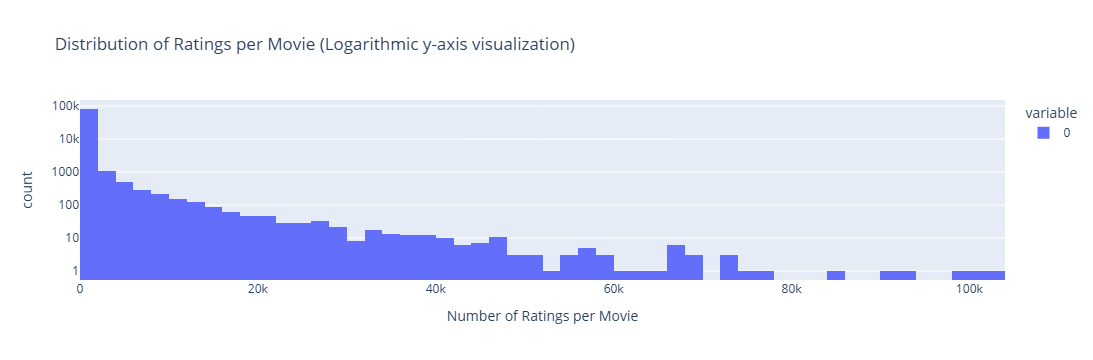

In [104]:
fig = px.histogram(
    movie_rating_counts,
    nbins=100,
    log_x=False,
    log_y=True,
    title="Distribution of Ratings per Movie (Logarithmic y-axis visualization)",
    labels={
        "value": "Number of Ratings per Movie",
        "count": "Number of Movies"
    })

fig.show()

In [105]:
# Finding top 20 most rated movies
top_movies = (
    movie_rating_counts
    .sort_values(ascending=False)
    .head(20)
    .rename_axis("movieId")
    .reset_index(name="rating_count")
)

top_movies = top_movies.merge(movies[["movieId", "title"]], on="movieId", how="left")

top_movies

,movieId,rating_count,title
0,318,102929,"Shawshank Redemption, The (1994)"
1,356,100296,Forrest Gump (1994)
2,296,98409,Pulp Fiction (1994)
3,2571,93808,"Matrix, The (1999)"
4,593,90330,"Silence of the Lambs, The (1991)"
5,260,85010,Star Wars: Episode IV - A New Hope (1977)
6,2959,77332,Fight Club (1999)
7,480,75233,Jurassic Park (1993)
8,527,73849,Schindler's List (1993)
9,4993,73122,"Lord of the Rings: The Fellowship of the Ring,..."


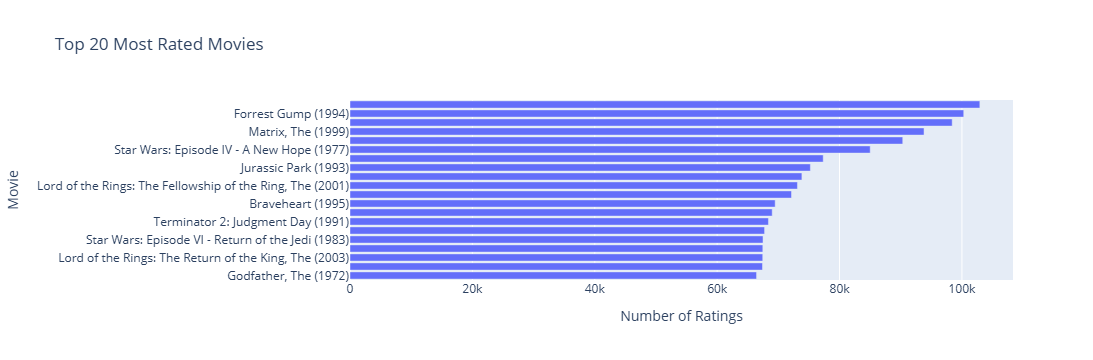

In [106]:
fig = px.bar(
    top_movies.sort_values("rating_count"),
    x="rating_count",
    y="title",
    orientation="h",
    title="Top 20 Most Rated Movies",
    labels={
        "rating_count": "Number of Ratings",
        "title": "Movie"
    })

fig.update_layout(yaxis_title="Movie", xaxis_title="Number of Ratings")

fig.show()

### Movie popularity observations

The number of ratings varies substantially across movies. The difference between the mean and median rating counts indicates that movie popularity is highly unevenly distributed.

A relatively small number of movies receive a large number of ratings, while many movies receive considerably fewer interactions.

The most frequently rated movies represent the most actively rated items in the dataset. However, rating count alone does not indicate whether users rated a movie positively or negatively.

These observations suggest that popularity may be useful as a baseline for recommendations, but it should not be treated as a complete measure of movie quality or individual user preference.

In [107]:
# Movie statistical table
movie_stats = (
    movie_rating_counts
    .rename("rating_count")
    .rename_axis("movieId")
    .reset_index()
)

movie_stats.head()

,movieId,rating_count
0,318,102929
1,356,100296
2,296,98409
3,2571,93808
4,593,90330
